# Eigenmode Simulation with dielectric trenching, film thickness and 3D air-bridges

A 3D simulation of a trenched CPW resonator with a finite-thickness film and air-bridges placed along the feedline and the resonator, simulated as 3D bridges.
* **Substrate trenching** - 10um trenches etched into the substrate under the CPW gaps (and under the lumped ports)
* **Film thickness** - the planar metals are extruded to 200nm; the bridges land on top of the film

### Qiskit Metal Design

In [ ]:
%matplotlib inline
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"
os.environ["PMIX_MCA_gds"]="hash"

# Import useful packages
from qiskit_metal import designs
from qiskit_metal import MetalGUI, Dict, open_docs
from SQDMetal.Utilities.QUtilities import QUtilities

# To create plots after geting solution data.
import matplotlib.pyplot as plt
import numpy as np

# Packages for the simple design
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.pathfinder import RoutePathfinder
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.terminations.short_to_ground import ShortToGround
from SQDMetal.Comps.AirBridges import AirBridgeCPW

# Set up chip design as planar, multiplanar also available
design = designs.DesignPlanar({}, overwrite_enabled=True)

# Set up chip dimensions 
design.chips.main.size.size_x = '3mm'
design.chips.main.size.size_y = '2mm'
design.chips.main.size.size_z = '500um'
design.chips.main.size.center_x = '0mm'
design.chips.main.size.center_y = '-0.7mm'

# Resonator and feedline gap width (W) and center conductor width (S) are set to 50 Ohm 
design.variables['cpw_width'] = '10 um' #S
design.variables['cpw_gap'] = '6 um' #W 

# Lauchpad 1
x1 = '-1.2mm'
y1 = '0mm'
launch_options1 = dict(chip='main', pos_x=x1, pos_y=y1, orientation='360', lead_length='30um', pad_height='103um', pad_width='103um', pad_gap='60um')
LP1 = LaunchpadWirebond(design, 'LP1', options = launch_options1)

# Launchpad 2
x2 = '1.2mm'
y1 = '0mm'
launch_options2 = dict(chip='main', pos_x=x2, pos_y=y1, orientation='180', lead_length='30um', pad_height='103um', pad_width='103um', pad_gap='60um')
LP2 = LaunchpadWirebond(design, 'LP2', options = launch_options2)

# Using path finder to connect the two launchpads
TL = RoutePathfinder(design, 'TL', 
        options = dict(chip='main', trace_width ='10um', trace_gap ='6um', fillet='90um', hfss_wire_bonds = True, 
            lead = dict(end_straight='0.1mm'),
            pin_inputs = dict(start_pin=Dict(component='LP1', pin='tie'), end_pin=Dict( component='LP2', pin='tie'))))


# lamba/4 resonator
otg1 = OpenToGround(design, 'otg1', options=dict(chip='main', pos_x='-0.2mm',  pos_y='-40um', orientation = 180))
stg1 = ShortToGround(design, 'stg1', options=dict(chip='main', pos_x='0mm',  pos_y='-1.35mm', orientation = -90))

# Use RouteMeander to fix the total length of the resonator
res1 = RouteMeander(design, 'resonator1', 
        options= Dict(trace_width ='10um', trace_gap ='6um', total_length='3.7mm', hfss_wire_bonds = False, fillet='99.9 um',
            lead = dict(start_straight='300um'),
            pin_inputs = dict(start_pin=Dict(component='otg1', pin='open'), end_pin=Dict(component='stg1', pin='short'))))


# Air bridges placed every 400um along the resonator
AirBridgeCPW(design, 'airbridges_res', 
        options=dict(pathObj='resonator1', layer=4, layer_bridge=5, dist_air_bridges='400um', dist_air_bridges_ends='50um'))

design.rebuild()
print(f"Airbridges: {len(design.components['airbridges_res'].current_positions)} on the resonator")

Airbridges: 6 on the resonator


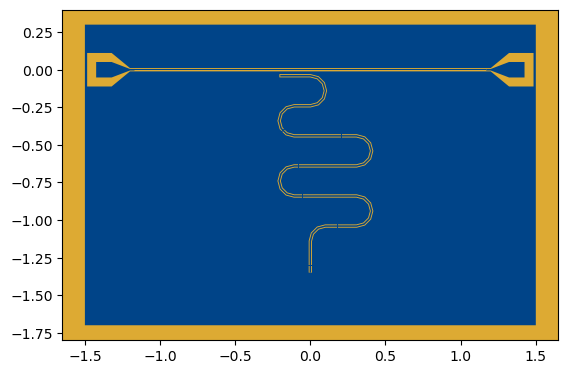

In [16]:
QUtilities.plot_all_components(design)

### Palace Eigenmode Simulation
(make sure to update the path to the Palace binary first)

In [ ]:
from SQDMetal.PALACE.Eigenmode_Simulation import PALACE_Eigenmode_Simulation
from SQDMetal.Utilities.Materials import MaterialInterface

#Eigenmode Simulation Options
user_defined_options = {
                 "mesh_refinement":  0,                             #refines mesh in PALACE - essetially divides every mesh element in half
                 "dielectric_material": "silicon",                  #choose dielectric material - 'silicon' or 'sapphire'
                 "starting_freq": 5e9,                              #starting frequency in Hz 
                 "number_of_freqs": 1,                              #number of eigenmodes to find
                 "solns_to_save": 1,                                #number of electromagnetic field visualizations to save
                 "solver_order": 2,                                 #increasing solver order increases accuracy of simulation, but significantly increases sim time
                 "solver_tol": 1.0e-8,                              #error residual tolerance foriterative solver
                 "solver_maxits": 200,                              #number of solver iterations
                 "fillet_resolution":12,                            #number of vertices per quarter turn on a filleted path
                 "palace_dir":"/Users/zd/Documents/Repos/spack/opt/spack/darwin-m1/palace-0.16.0-ieocqz4heqvvzrlbqx3v5lnnzibxvzrg/bin/palace",#"PATH/TO/PALACE/BINARY",
                 "num_cpus": 8                                     #number of cpus to use in the simulation
                }

#Creat the Palace Eigenmode simulation
eigen_sim = PALACE_Eigenmode_Simulation(name ='res_eigen_trenched_airbridges',                              #name of simulation
                                        metal_design = design,                                      #feed in qiskit metal design
                                        sim_parent_directory = "",            #choose directory where mesh file, config file and HPC batch file will be saved
                                        mode = 'simPC',                                               #choose simulation mode 'HPC' or 'simPC'                                          
                                        meshing = 'GMSH',                                         #choose meshing 'GMSH' or 'COMSOL'
                                        user_options = user_defined_options,                        #provide options chosen above
                                        create_files = True)                                        #create mesh, config and HPC batch files

#Add in metals from layer 1 of the design file
eigen_sim.add_metallic(1)

#Add in ground plane for simulation
eigen_sim.add_ground_plane()

#Add in lumped element ports on launcher pads for 50 Ohm matching
eigen_sim.create_port_CPW_on_Launcher('LP1', 20e-6)
eigen_sim.create_port_CPW_on_Launcher('LP2', 20e-6)

#Full 3D: finite film thickness for the planar metals and 10um trenches etched into the substrate gaps
film_thickness = 200e-9
eigen_sim.enforce_full_3D_simulation(film_thickness, substrate_trenching=10e-6)

#Fine mesh the resonator, launch apds and transmission line
eigen_sim.fine_mesh_components(['TL', 'resonator1', 'LP1', 'LP2'], min_size=10e-6, max_size=200e-6, taper_dist_min=10e-6, metals_only=False)

#3D air-bridges from the AirBridgeCPW components
#  - cross_section: 'solid' (finite-thickness film) or 'sheet' (zero-thickness). Meshing this example takes ~13 min
#                   with 'solid' bridges vs ~3 min with 'sheet' bridges.
#  - height: clearance from the top of the planar film to the underside of the deck
#  - profile: 'arch' (reflowed resist), 'flat' (posts + flat deck), 'trapezoid', ...
eigen_sim.set_airbridge_defaults(cross_section='solid', height=3e-6, thickness=1e-6, profile='arch', material='Al')
print(f"Added {eigen_sim.add_airbridges_from_design()} 3D air-bridges along `resonator1`.")

#Sets up the lossy interfaces for MA, SA and MS interfaces 
eigen_sim.setup_EPR_interfaces(metal_air=MaterialInterface('Aluminium-Vacuum'), substrate_air=MaterialInterface('Silicon-Vacuum'), substrate_metal=MaterialInterface('Silicon-Aluminium'))

#Only works in v0.14
# eigen_sim.set_farfield(ff_type='conductor', ff_material=MaterialConductor("OFHC"), ff_plane='z_neg')

#Prepares the mesh file and config file
eigen_sim.prepare_simulation()

Added 6 3D air-bridges along `resonator1`.


Check what the simulation built: each bridge should be a `ground_stitch` (ground on both sides, crossing the CPW trace) with no warnings. Optionally inspect the mesh in the Gmsh GUI (blocks until the window is closed).

In [18]:
# print a summary of the wirebonds
# note that this prints their conductor group, here conductor 0 - ground plane.
eigen_sim.get_wirebond_summary();

ab_airbridges_res_0 (airbridge): ground_stitch [ground] ground(0) -> ground(0), span=47.0um, BC=pec, conductor=0
ab_airbridges_res_1 (airbridge): ground_stitch [ground] ground(0) -> ground(0), span=47.0um, BC=pec, conductor=0
ab_airbridges_res_2 (airbridge): ground_stitch [ground] ground(0) -> ground(0), span=47.0um, BC=pec, conductor=0
ab_airbridges_res_3 (airbridge): ground_stitch [ground] ground(0) -> ground(0), span=47.0um, BC=pec, conductor=0
ab_airbridges_res_4 (airbridge): ground_stitch [ground] ground(0) -> ground(0), span=47.0um, BC=pec, conductor=0
ab_airbridges_res_5 (airbridge): ground_stitch [ground] ground(0) -> ground(0), span=47.0um, BC=pec, conductor=0


In [ ]:
# # optionally, inspect the mesh
# eigen_sim.open_mesh_gmsh()

In [19]:
#run the simulation
eigen_sim.run()

>> /Users/zd/miniforge3/envs/sqdmetal/bin/mpirun -n 8 /Users/zd/Documents/Repos/spack/opt/spack/darwin-m1/palace-0.16.0-ieocqz4heqvvzrlbqx3v5lnnzibxvzrg/bin/palace-arm64.bin res_eigen_trenched_airbridges.json

_____________     _______
_____   __   \____ __   /____ ____________
____   /_/  /  __ ` /  /  __ ` /  ___/  _ \
___   _____/  /_/  /  /  /_/  /  /__/  ___/
  /__/     \___,__/__/\___,__/\_____\_____/


--> Warning!
Output folder is not empty; program will overwrite content! (outputFiles)
Git changeset ID: 869ee5c
Running with 8 MPI processes
Device configuration: cpu
Memory configuration: host-std
libCEED backend: /cpu/self/opt/blocked

Added 15945 duplicate vertices for interior boundaries in the mesh
Added 31770 duplicate boundary elements for interior boundaries in the mesh
Added 1342 boundary elements for material interfaces to the mesh
Finished partitioning mesh into 8 subdomains

Characteristic length and time scales:
 Lc = 3.600e-03 m, tc = 1.201e-02 ns

Mesh curvature or

--------------------------------------------------------------------------
prterun has exited due to process rank 3 with PID 12673 on node SMP-K0XH14HD2R exiting
improperly. There are three reasons this could occur:

1. this process did not call "init" before exiting, but others in the
job did. This can cause a job to hang indefinitely while it waits for
all processes to call "init". By rule, if one process calls "init",
then ALL processes must call "init" prior to termination.

2. this process called "init", but exited without calling "finalize".
By rule, all processes that call "init" MUST call "finalize" prior to
exiting or it will be considered an "abnormal termination"

3. this process called "MPI_Abort" or "prte_abort" and the mca
parameter prte_create_session_dirs is set to false. In this case, the
run-time cannot detect that the abort call was an abnormal
termination. Hence, the only error message you will receive is this
one.

This may have caused other processes in the applic

Error in plotting: 'E_real'


array([[1.00000000e+00, 1.18450012e+01, 3.44113434e-04, 1.72108963e+04,
        2.16979159e-12, 1.18305195e-05]])

The data will be stored in the output directory along with pregenerated plots slicing the device plane. Nonetheless, the slices can be manually retrieved via the `PVDVTU_Viewer` class. Either initialise the class directly or via the returned object when calling `retrieve_field_plots`:

Plot saved: /Users/zd/Documents/Repos/NQCT-DesignDesk/Examples/res_eigen_trenched_airbridges/outputFiles/eigenmodes.png


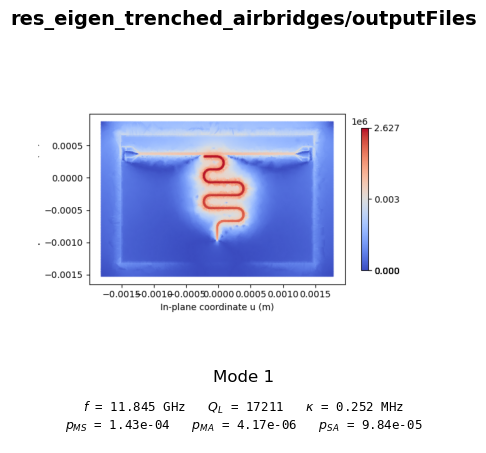

{'mode_dict': {'mat_mode_port': None,
  'eigenfrequencies': array([1.18450012e+10]),
  'loaded_Q': array([17210.89631205]),
  'kappa': array([0.00025188])},
 'participations': [{'Frequency': (11845001247.980001+344113.4336706j),
   'Q': 17210.89631205,
   'SA': {'p': 9.841393288453e-05, 'Q': 1693527.143786},
   'MS': {'p': 0.0001426179195531, 'Q': 23372472.01318},
   'MA': {'p': 4.174525930953e-06, 'Q': 479096317.3017}}]}

In [20]:
# plot the fields mode frequency, Q, and participation ratios
eigen_sim.plot_fields_with_data()

Slicing vertically through an air-bridge on the feedline shows the trenches and the bridge spanning the CPW...

PVDVTU_Slice.plot: removed 20 degenerate triangle(s) out of 15209.


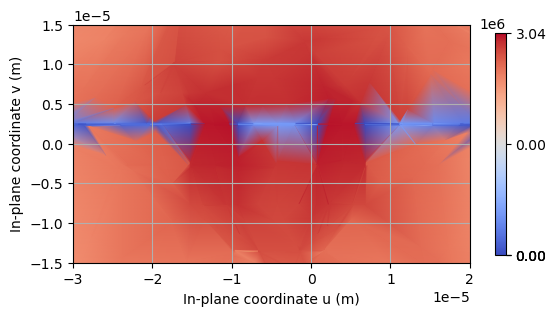

In [30]:
#Vertical slice across the feedline through its first air-bridge (current_positions are in mm)
x_bridge = design.components['airbridges_res'].current_positions[1][0] * 1e-3
%matplotlib inline
pvdtu = eigen_sim.retrieve_field_plots()
leSlice = pvdtu.get_data_slice(0, slice_plane_normal=np.array([1,0,0]), slice_plane_origin=np.array([x_bridge,0,0]), vec_x_axis=np.array([0,1,0]))
fig, ax = plt.subplots(1)
leSlice.plot(np.linalg.norm(leSlice.get_data('E_real'), axis=1), 'coolwarm', True, ax=ax)
ax.set_xlim([-30e-6,20e-6])
ax.set_ylim([-15e-6,15e-6])
ax.grid()